# Projet – Reinforcement Learning
Title: Designing and Evaluation

Taxi-v3 (pick up and drop off passengers efficiently)

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import deque
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
env = gym.make("Taxi-v3").env


In [3]:
env.reset() # reset environment to a new, random state
env.render()

print("Action Space {}".format(env.action_space))
print("State Space {}".format(env.observation_space))


Action Space Discrete(6)
State Space Discrete(500)


/usr/local/lib/python3.12/dist-packages/gymnasium/envs/toy_text/taxi.py:443: UserWarning: WARN: You are calling render method without specifying any render mode. You can specify the render_mode at initialization, e.g. gym.make("Taxi-v3", render_mode="rgb_array")
  gym.logger.warn(


# Q-Learning

In [4]:
# Hyperparameters
alpha = 0.1      # learning rate
gamma = 0.95     # discount factor
epsilon = 1.0    # exploration rate
epsilon_min = 0.01
epsilon_decay = 0.995
episodes = 3000

# Q-table initialization
q_table = np.zeros((env.observation_space.n, env.action_space.n))

# For plotting
rewards_per_episode = []
successes = []

for i in range(episodes):
    state, _ = env.reset()
    total_reward = 0
    terminated = False
    truncated = False

    while not terminated and not truncated:
        # Epsilon-greedy action selection
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()  # Explore
        else:
            action = np.argmax(q_table[state])  # Exploit

        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward

        # Q-learning update
        best_future_q = np.max(q_table[next_state])
        td_target = reward + gamma * best_future_q
        td_error = td_target - q_table[state][action]
        q_table[state][action] += alpha * td_error

        state = next_state

    # Track metrics
    rewards_per_episode.append(total_reward)
    successes.append(1 if reward == 20 else 0)  # Success = got +20 for dropoff

    # Decay epsilon
    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

print("Q-Learning training completed.")


Q-Learning training completed.


# Deep RL method (DQN)

In [5]:
class DQN(nn.Module):
    def __init__(self, input_size, output_size):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, output_size)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [6]:
# Hyperparameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_size = env.observation_space.n
output_size = env.action_space.n

policy_net = DQN(input_size, output_size).to(device)
target_net = DQN(input_size, output_size).to(device)
target_net.load_state_dict(policy_net.state_dict())  # Sync weights
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=1e-3)
replay_buffer = deque(maxlen=2000)
batch_size = 64
tau = 0.005   # target network update rate
C = 10        # update target every C steps

epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995
episodes = 3000

# Helper: One-hot encode state
def one_hot_state(state, n=500):
    vec = np.zeros(n)
    vec[state] = 1
    return vec

# For plotting
dqn_rewards = []
dqn_successes = []

steps_done = 0

for i in range(episodes):
    state, _ = env.reset()
    state_vec = one_hot_state(state)
    total_reward = 0
    terminated = False
    truncated = False

    while not terminated and not truncated:
        # Epsilon-greedy using DQN
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                state_tensor = torch.FloatTensor(state_vec).unsqueeze(0).to(device)
                q_values = policy_net(state_tensor)
                action = q_values.argmax().item()

        next_state, reward, terminated, truncated, _ = env.step(action)
        next_state_vec = one_hot_state(next_state)

        total_reward += reward

        # Store transition
        replay_buffer.append((state_vec, action, reward, next_state_vec, terminated))

        state = next_state
        state_vec = next_state_vec
        steps_done += 1

        # Train DQN if enough samples
        if len(replay_buffer) >= batch_size:
            batch = random.sample(replay_buffer, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)

            states = torch.FloatTensor(np.array(states)).to(device)
            actions = torch.LongTensor(np.array(actions)).unsqueeze(1).to(device)
            rewards = torch.FloatTensor(rewards).to(device)
            next_states = torch.FloatTensor(np.array(next_states)).to(device)
            dones = torch.BoolTensor(dones).to(device)

            current_q = policy_net(states).gather(1, actions)
            next_q = target_net(next_states).max(1)[0].detach()
            target_q = rewards + gamma * next_q * (~dones)
            target_q = target_q.unsqueeze(1)

            loss = nn.MSELoss()(current_q, target_q)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Soft update of target network
            if steps_done % C == 0:
                for target_param, policy_param in zip(target_net.parameters(), policy_net.parameters()):
                    target_param.data.copy_(tau * policy_param.data + (1 - tau) * target_param.data)

    dqn_rewards.append(total_reward)
    dqn_successes.append(1 if reward == 20 else 0)

    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

print("DQN training completed.")

DQN training completed.


# Plot learning curves

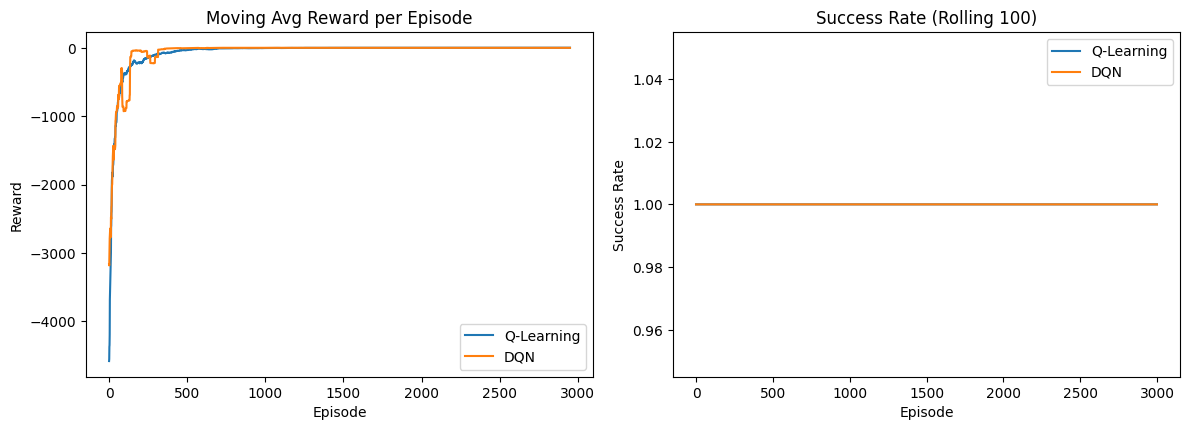

In [7]:
def moving_average(data, window=50):
    return np.convolve(data, np.ones(window)/window, mode='valid')

plt.figure(figsize=(12, 8))

# Average reward
plt.subplot(2, 2, 1)
plt.plot(moving_average(rewards_per_episode), label="Q-Learning")
plt.plot(moving_average(dqn_rewards), label="DQN")
plt.title("Moving Avg Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.legend()

# Success rate
plt.subplot(2, 2, 2)
success_rate_ql = [np.mean(successes[max(0,i-100):i+1]) for i in range(len(successes))]
success_rate_dqn = [np.mean(dqn_successes[max(0,i-100):i+1]) for i in range(len(dqn_successes))]
plt.plot(success_rate_ql, label="Q-Learning")
plt.plot(success_rate_dqn, label="DQN")
plt.title("Success Rate (Rolling 100)")
plt.xlabel("Episode")
plt.ylabel("Success Rate")
plt.legend()

plt.tight_layout()
plt.show()

# Visualize the learned policy

In [8]:
def test_agent(env, q_table=None, dqn=None, num_tests=3):
    for i in range(num_tests):
        state, _ = env.reset()
        print(f"\n--- Test Run {i+1} ---")
        terminated = False
        truncated = False
        step = 0
        while not terminated and not truncated:
            print(env.render())  # Show text-based grid
            if dqn:
                state_vec = one_hot_state(state)
                state_tensor = torch.FloatTensor(state_vec).unsqueeze(0).to(device)
                action = dqn(state_tensor).argmax().item()
            else:
                action = np.argmax(q_table[state])
            state, reward, terminated, truncated, _ = env.step(action)
            print(f"Action: {action}, Reward: {reward}")
            step += 1
            if step > 50:
                print("Too many steps, breaking.")
                break
        print("Done.")

In [9]:
env = gym.make("Taxi-v3", render_mode="ansi")  # For text rendering
test_agent(env, q_table=q_table)  # Test Q-Learning agent


--- Test Run 1 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


Action: 1, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

Action: 2, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Action: 2, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Action: 2, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Action: 0, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

Action: 0, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

Action: 4, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)

Action: 1, Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : |